**Источники:**
1) [Development and validation of a multi-stage self-supervised learning model for optical coherence tomography image classification](https://academic.oup.com/jamia/article/32/5/800/8051867#512283058) 

In [1]:
from pathlib import Path
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from PIL import Image, ImageOps, ImageChops, ImageEnhance, ImageFilter
import cv2
from tqdm.auto import tqdm

## Загрузка данных

In [2]:
dataset_path = Path("ZhangLabData\CellData\OCT")

extensions = {".jpeg"}

images = [
    f for f in dataset_path.rglob("*")
    if f.is_file()
    and f.suffix.lower() in extensions
    and "__MACOSX" not in f.parts
    and not f.name.startswith("._")
]

print(f"Всего изображений: {len(images):,}")

class_counts = Counter(
    cls
    for f in images
    for cls in ["CNV", "DME", "DRUSEN", "NORMAL"]
    if cls in f.parts
)

df = pd.DataFrame(
    class_counts.items(),
    columns=["Class", "Count"]
).sort_values("Class")

display(df)

Всего изображений: 109,309


,Class,Count
0,CNV,37455
1,DME,11598
2,DRUSEN,8866
3,NORMAL,51390


## Каталог аугментаций

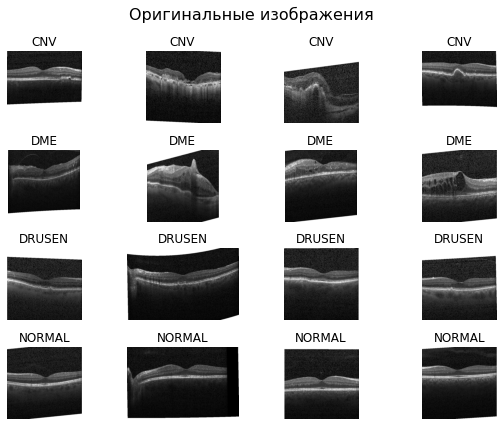

In [3]:
classes = ["CNV", "DME", "DRUSEN", "NORMAL"]

random.seed(42)

fig, axes = plt.subplots(4, 4, figsize=(8, 6))

for i, cls in enumerate(classes):

    class_images = [
        f for f in images
        if cls in f.parts
    ]

    selected = random.sample(class_images, 4)

    for j, img_path in enumerate(selected):
        with Image.open(img_path) as img:
            axes[i, j].imshow(img.convert("L"), cmap="gray")

        axes[i, j].set_title(cls)
        axes[i, j].axis("off")

plt.suptitle("Оригинальные изображения", fontsize=16)
plt.tight_layout()
plt.show()

### 1. Горизонтальный flip

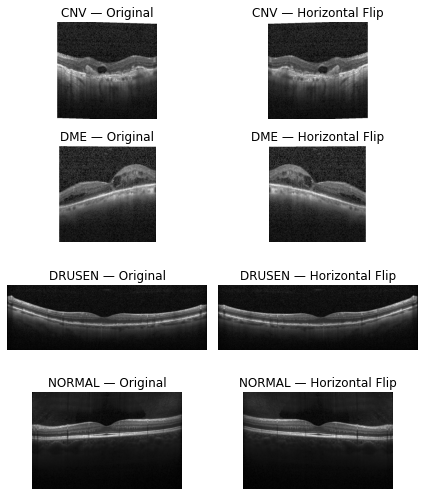

In [4]:
selected_images = {}

for cls in classes:
    class_images = [
        f for f in images
        if cls in f.parts
    ]
    selected_images[cls] = random.choice(class_images)

fig, axes = plt.subplots(4, 2, figsize=(6, 7))

for i, cls in enumerate(classes):
    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    flipped = ImageOps.mirror(original)

    axes[i, 0].imshow(original, cmap="gray")
    axes[i, 0].set_title(f"{cls} — Original")

    axes[i, 1].imshow(flipped, cmap="gray")
    axes[i, 1].set_title(f"{cls} — Horizontal Flip")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

### 2. Поворот изображения

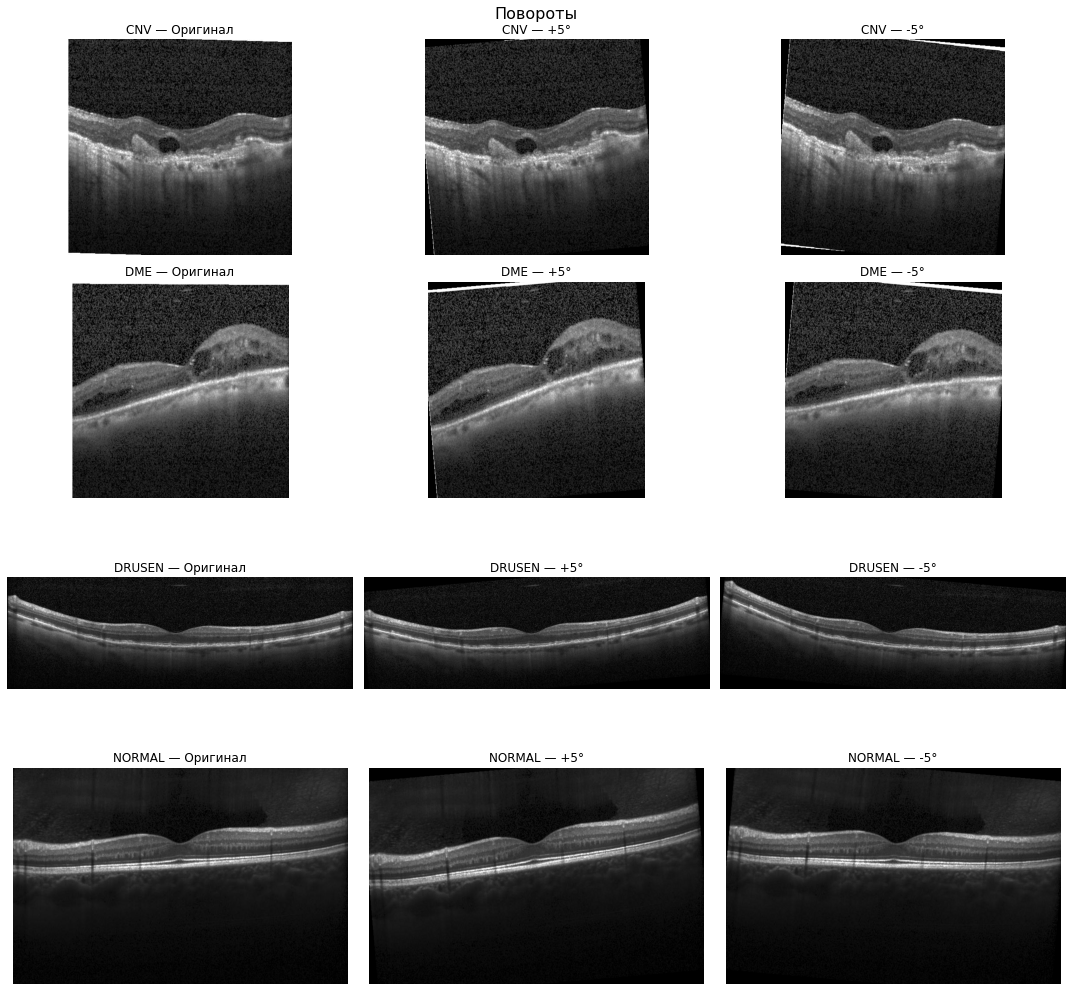

In [5]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for i, cls in enumerate(classes):

    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    rotated_left = original.rotate(
        5,
        resample=Image.BICUBIC,
        fillcolor=0
    )

    rotated_right = original.rotate(
        -5,
        resample=Image.BICUBIC,
        fillcolor=0
    )

    variants = [
        (original, "Оригинал"),
        (rotated_left, "+5°"),
        (rotated_right, "-5°")
    ]

    for j, (image, title) in enumerate(variants):
        axes[i, j].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"{cls} — {title}")
        axes[i, j].axis("off")

plt.suptitle("Повороты", fontsize=16)
plt.tight_layout()
plt.show()

### 3. Сдвиг

In [6]:
def shift_image(img, dx=0, dy=0):
    """
    Выполняет сдвиг изображения по горизонтали и вертикали.
    img — исходное изображение
    dx — сдвиг по горизонтали в пикселях
         (положительное значение — вправо, отрицательное — влево)
    dy — сдвиг по вертикали в пикселях
         (положительное значение — вниз, отрицательное — вверх)
    """
    return img.transform(
        img.size,
        Image.AFFINE,
        (1, 0, -dx, 0, 1, -dy),
        resample=Image.BICUBIC,
        fillcolor=0
    )

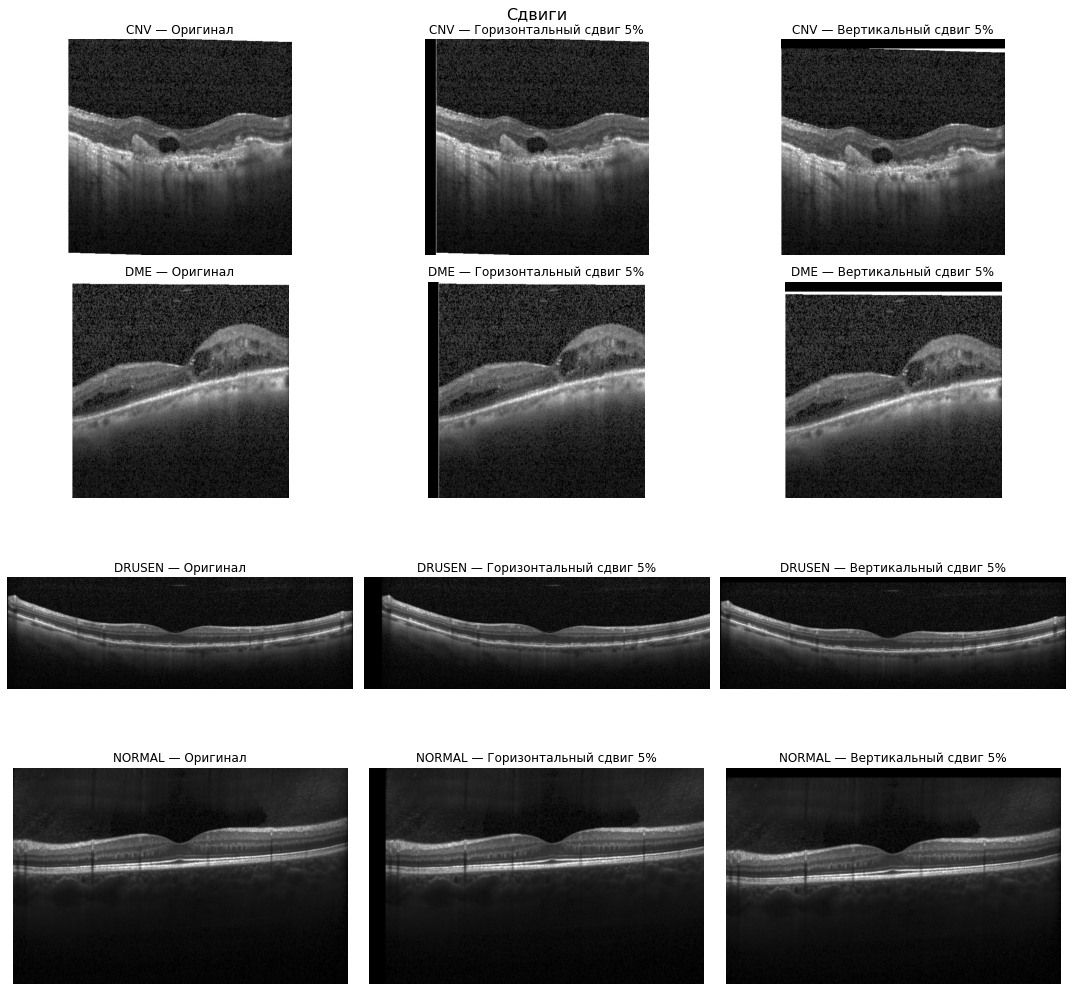

In [7]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))

for i, cls in enumerate(classes):

    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    width, height = original.size

    dx = int(width * 0.05)
    dy = int(height * 0.05)

    # Горизонтальный сдвиг
    shift_horizontal = shift_image(original, dx, 0)

    # Вертикальный сдвиг
    shift_vertical = shift_image(original, 0, dy)

    variants = [
        (original, "Оригинал"),
        (shift_horizontal, "Горизонтальный сдвиг 5%"),
        (shift_vertical, "Вертикальный сдвиг 5%")
    ]

    for j, (image, title) in enumerate(variants):
        axes[i, j].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"{cls} — {title}")
        axes[i, j].axis("off")

plt.suptitle("Сдвиги", fontsize=16)
plt.tight_layout()
plt.show()

**Вывод:** Для оценки возможности повышения устойчивости модели к изменениям положения изображений были применены небольшие повороты и сдвиги OКT-снимков.

В рамках эксперимента использовались **повороты на 5° и сдвиги на 5% от размера изображения**. Преобразования были рассмотрены для четырёх диагностических классов: CNV, DME, DRUSEN и NORMAL.

Такие аугментации потенциально могут улучшить обобщающую способность модели, позволяя ей распознавать патологические изменения независимо от небольших отклонений в положении снимка.

Однако данные преобразования имеют определённые ограничения. При поворотах могут возникать искусственные границы, а при сдвигах — обрезаться участки изображения, содержащие диагностически значимые структуры сетчатки. Непонятно, насколько распространена ситуация таких преобразований изображения в реальной жизни.

Для проверки целесообразности использования требуется сравнение с бейзлайном

### 4. Яркость и контрастность

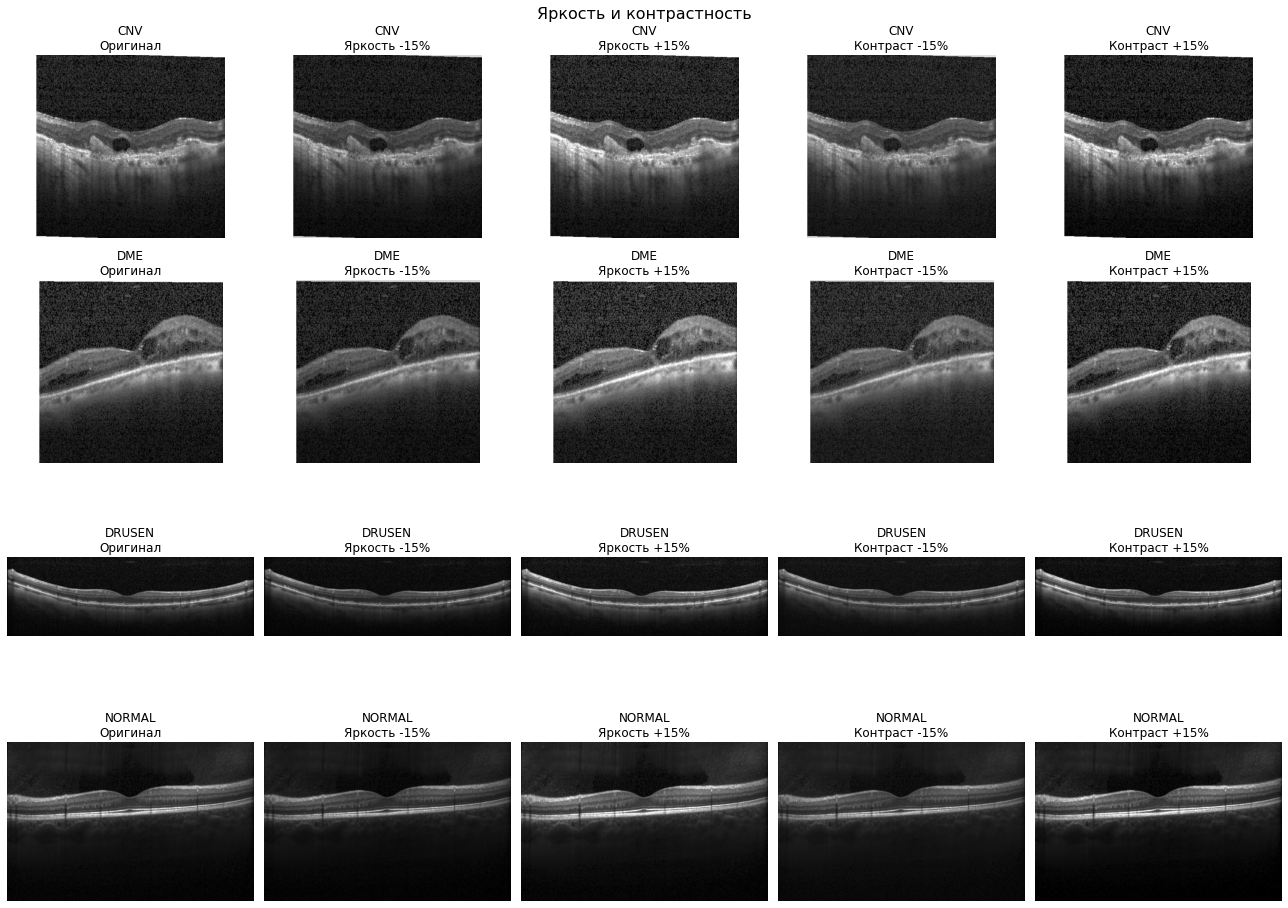

In [8]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13))

for i, cls in enumerate(classes):
    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    variants = [
        (original, "Оригинал"),
        (ImageEnhance.Brightness(original).enhance(0.85), "Яркость -15%"),
        (ImageEnhance.Brightness(original).enhance(1.15), "Яркость +15%"),
        (ImageEnhance.Contrast(original).enhance(0.85), "Контраст -15%"),
        (ImageEnhance.Contrast(original).enhance(1.15), "Контраст +15%")
    ]

    for j, (image, title) in enumerate(variants):
        axes[i, j].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"{cls}\n{title}")
        axes[i, j].axis("off")

plt.suptitle("Яркость и контрастность", fontsize=16)
plt.tight_layout()
plt.show()

#### Изменение яркости

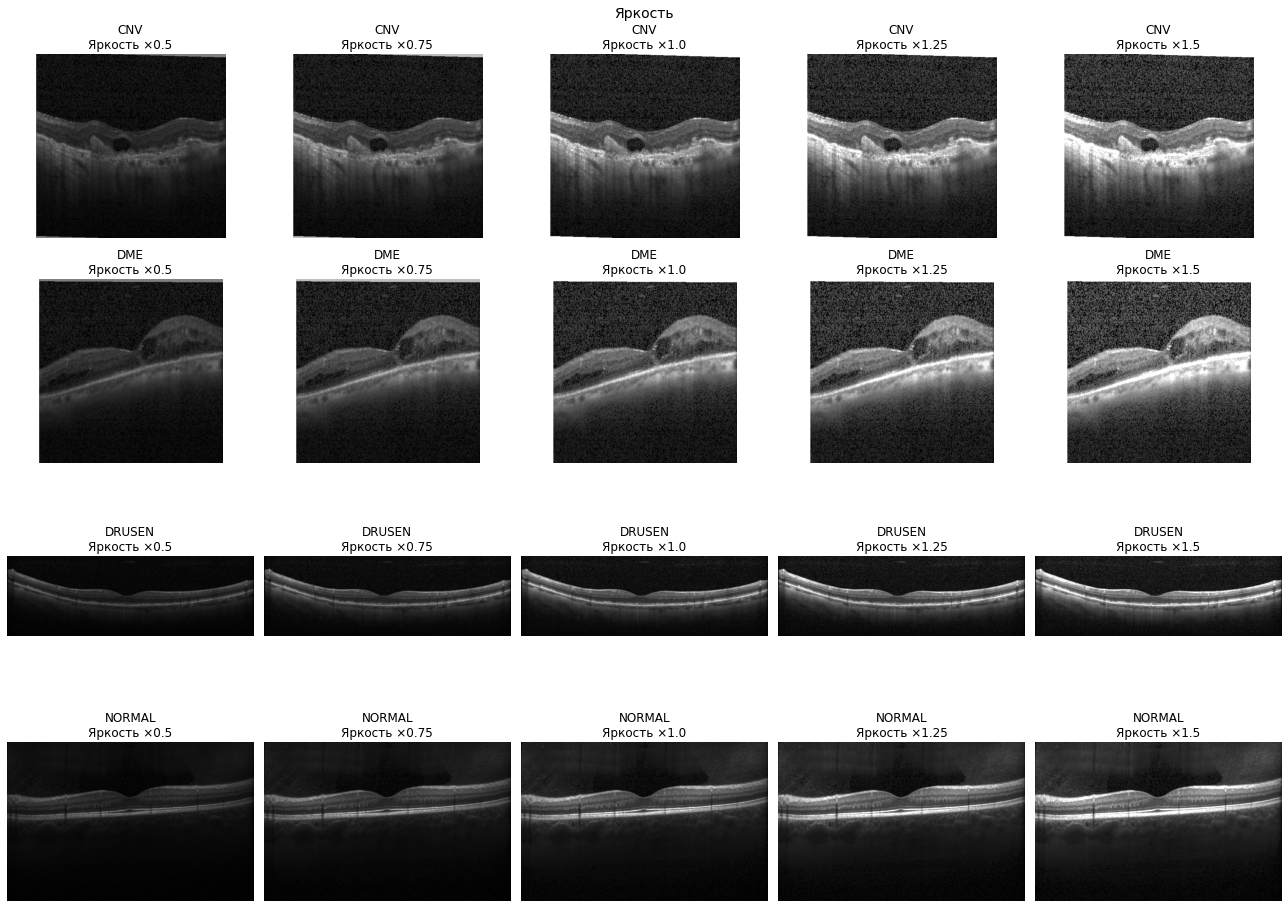

In [9]:
brightness_factors = np.arange(0.5, 1.75, 0.25)

fig, axes = plt.subplots(4, 5, figsize=(18, 13))

for i, cls in enumerate(classes):

    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    for j, factor in enumerate(brightness_factors):

        augmented = ImageEnhance.Brightness(
            original
        ).enhance(factor)

        axes[i, j].imshow(
            augmented,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[i, j].set_title(
            f"{cls}\nЯркость ×{factor}"
        )
        axes[i, j].axis("off")

plt.suptitle("Яркость", fontsize=14)
plt.tight_layout()
plt.show()

#### Изменение контраста

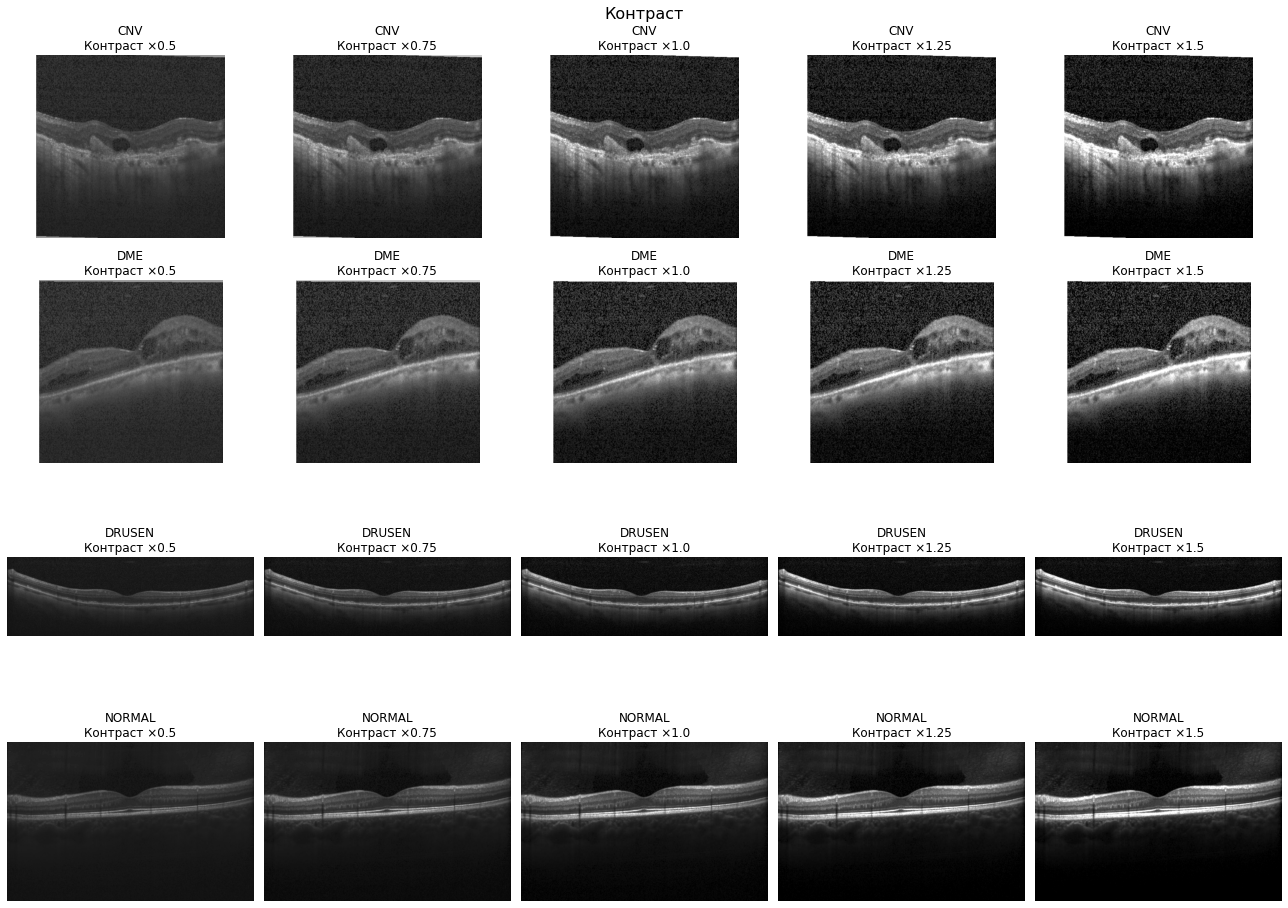

In [10]:
contrast_factors = np.arange(0.5, 1.75, 0.25)

fig, axes = plt.subplots(4, 5, figsize=(18, 13))

for i, cls in enumerate(classes):

    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    for j, factor in enumerate(contrast_factors):

        augmented = ImageEnhance.Contrast(
            original
        ).enhance(factor)

        axes[i, j].imshow(
            augmented,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[i, j].set_title(
            f"{cls}\nКонтраст ×{factor}"
        )
        axes[i, j].axis("off")

plt.suptitle("Контраст", fontsize=16)
plt.tight_layout()
plt.show()

**Вывод:** При изменении яркости и контраста на 15% визуально большой разницы не видно. Относительно заметно становится при изменении на 25% и более.


## 5. Масштаб

In [11]:
def zoom_image(img, factor=1.1):
    """
    Выполняет масштабирование изображения с сохранением исходного размера.

    img — исходное изображение
    factor — коэффициент масштабирования
    """

    w, h = img.size

    if factor == 1:
        return img.copy()

    if factor > 1:
        new_w = int(w / factor)
        new_h = int(h / factor)
        left = (w - new_w) // 2
        top = (h - new_h) // 2
        cropped = img.crop((
            left, top,
            left + new_w,
            top + new_h
        ))
        return cropped.resize((w, h),  Image.BICUBIC)
    else:
        new_w = int(w * factor)
        new_h = int(h * factor)
        resized = img.resize((new_w, new_h), Image.BICUBIC)
        result = Image.new(img.mode, (w, h), 0)
        left = (w - new_w) // 2
        top = (h - new_h) // 2
        result.paste(resized, (left, top))
        return result

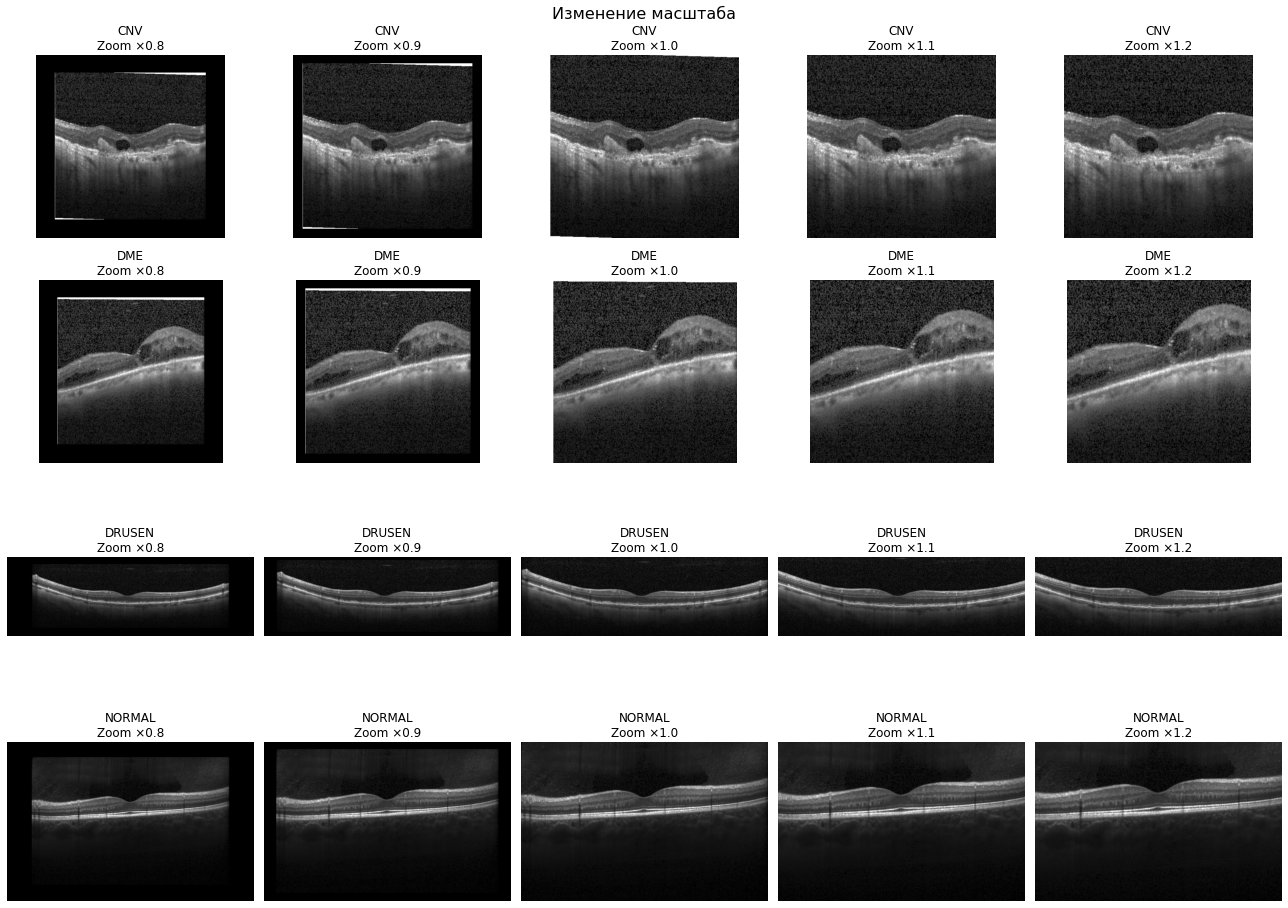

In [12]:
zoom_factors = np.arange(0.8, 1.3, 0.1)

fig, axes = plt.subplots(4, 5, figsize=(18, 13))

for i, cls in enumerate(classes):

    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    for j, factor in enumerate(zoom_factors):

        augmented = zoom_image(original, factor)

        axes[i, j].imshow(
            augmented,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[i, j].set_title(
            f"{cls}\nZoom ×{factor}"
        )
        axes[i, j].axis("off")

plt.suptitle("Изменение масштаба", fontsize=16)
plt.tight_layout()
plt.show()

**Вывод:** Изменение масштаба более, чем на 0.1 сильно влияет на изображение, что может ухудшить качество модели.

### 6. Gaussian Blur

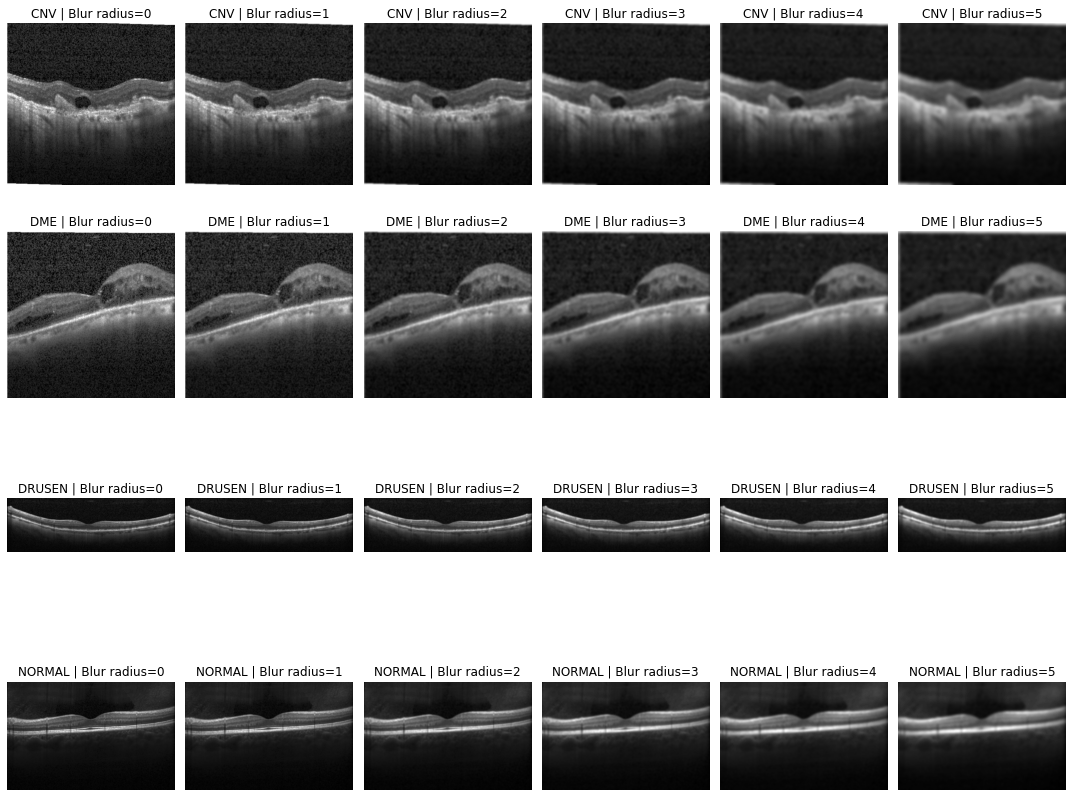

In [13]:
blur_radius = np.arange(0, 6)

fig, axes = plt.subplots(4, 6, figsize=(15, 12))

for i, cls in enumerate(classes):
    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")

    for j, radius in enumerate(blur_radius):
        augmented = original.filter(
            ImageFilter.GaussianBlur(radius=radius)
        )

        axes[i, j].imshow(augmented, cmap="gray")
        axes[i, j].set_title(f"{cls} | Blur radius={radius}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

**Выводы:** визуально различие становится заметно при радиусе от 3-х. Для обучения предлагаются к использованию размытия с радиусом 2 и 3.

## Каталог

In [14]:
def random_crop(img, crop_fraction=0.1, seed=42):
    """
    Выполняет случайное кадрирование изображения с сохранением исходного размера.
    img — исходное изображение
    crop_fraction — доля обрезаемой ширины и высоты изображения:
    seed — для воспроизводимости результатов
    """

    rng = np.random.default_rng(seed)

    w, h = img.size
    crop_w = max(1, int(w * (1 - crop_fraction)))
    crop_h = max(1, int(h * (1 - crop_fraction)))

    left = int(rng.integers(0, w - crop_w + 1))
    top = int(rng.integers(0, h - crop_h + 1))

    cropped = img.crop((
        left, top,
        left + crop_w,
        top + crop_h
    ))

    return cropped.resize((w, h), Image.BICUBIC)


def get_augmentations(img):
    """
    Выполняет преобразования выше к каждому изображению
    """   
    w, h = img.size

    return {
        "Оригинал": img,
        "Горизонтальное отражение": ImageOps.mirror(img),
        "Поворот -5°": img.rotate(
            -5, resample=Image.BICUBIC, fillcolor=0
        ),
        "Поворот +5°": img.rotate(
            5, resample=Image.BICUBIC, fillcolor=0
        ),
        "Горизонтальныый сдвиг 5%": shift_image(
            img, dx=int(w * 0.05)
        ),
        "Вертикальный сдвиг 5%": shift_image(
            img, dy=int(h * 0.05)
        ),
        "Яркость -25%": ImageEnhance.Brightness(
            img
        ).enhance(0.75),
        "Яркость +25%": ImageEnhance.Brightness(
            img
        ).enhance(1.25),
        "Контраст -25%": ImageEnhance.Contrast(
            img
        ).enhance(0.75),
        "Контраст +25%": ImageEnhance.Contrast(
            img
        ).enhance(1.25),
        "Масштаб ×1.1": zoom_image(img, 1.1),
        "Масштаб ×0.9": zoom_image(img, 0.9),
        "Random Crop 5%": random_crop(img, 0.05),
        "Random Crop 10%": random_crop(img, 0.10),
        "Random Crop 20%": random_crop(img, 0.20),
        "Gaussian Blur R=1":  img.filter(
    ImageFilter.GaussianBlur(radius=1.0)
)
    }

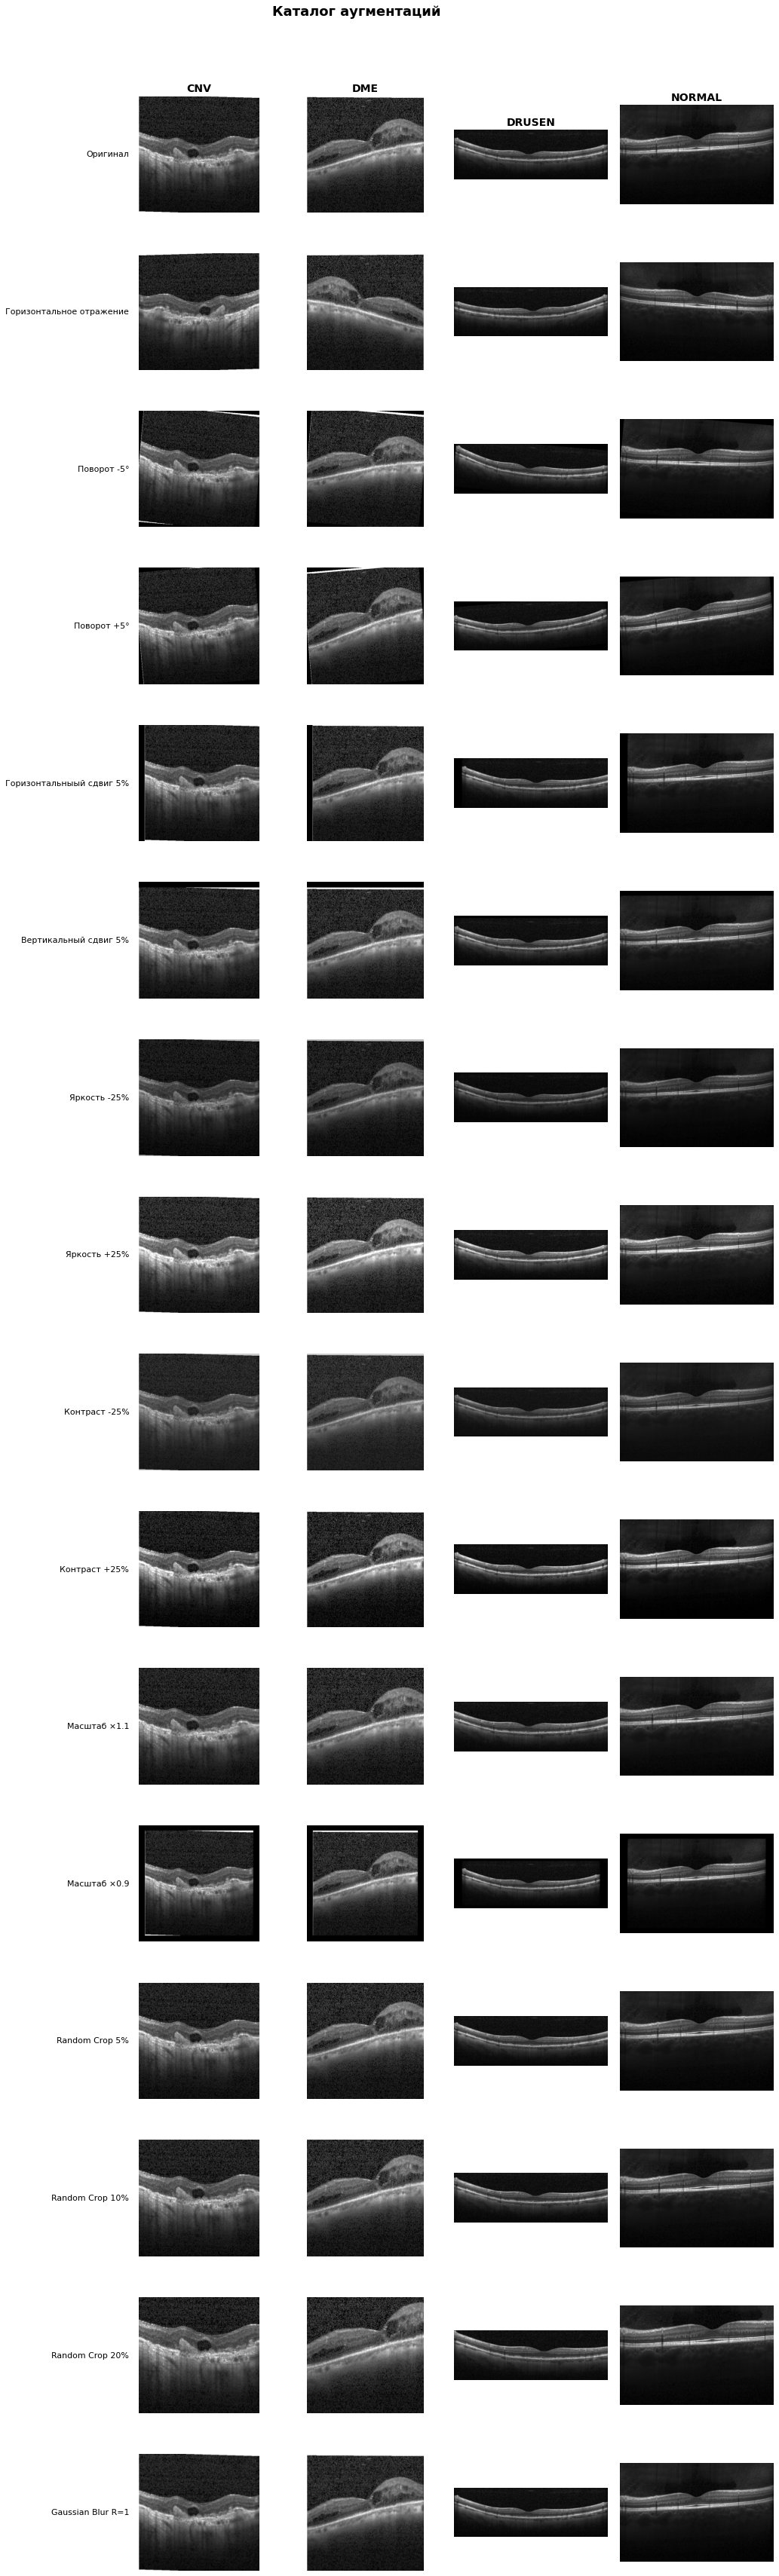

In [15]:
classes = ["CNV", "DME", "DRUSEN", "NORMAL"]

augmented_data = {}

for cls in classes:
    with Image.open(selected_images[cls]) as img:
        original = img.convert("L")
        augmented_data[cls] = get_augmentations(original)

aug_names = list(augmented_data[classes[0]].keys())

fig, axes = plt.subplots(
    len(aug_names),
    len(classes),
    figsize=(16, 3 * len(aug_names))
)

for i, aug_name in enumerate(aug_names):
    for j, cls in enumerate(classes):

        axes[i, j].imshow(
            augmented_data[cls][aug_name],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[i, j].axis("off")

        if i == 0:
            axes[i, j].set_title(
                cls, fontsize=14, fontweight="bold"
            )

        if j == 0:
            axes[i, j].text(
                -0.08, 0.5,
                aug_name,
                transform=axes[i, j].transAxes,
                ha="right",
                va="center",
                fontsize=11
            )

plt.suptitle(
    "Каталог аугментаций",
    fontsize=18,
    fontweight="bold",
    y=1.005
)

plt.subplots_adjust(
    left=0.23,
    right=0.98,
    top=0.97,
    bottom=0.02,
    hspace=0.35,
    wspace=0.08
)

plt.show()

In [16]:
output_dir = Path("results/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "oct_augmentation_catalog_sample.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

## Оценка медицинской допустимости аугментаций OКT-изображений

Оптическая когерентная томография (OКT) позволяет визуализировать поперечную структуру сетчатки глаза. В отличие от обычных фотографий, OКT-изображения содержат диагностически значимую информацию о расположении и толщине слоёв сетчатки, наличии жидкости, друз и других патологических изменений.

При использовании аугментаций важно не только увеличить разнообразие обучающих данных, но и сохранить анатомическую достоверность изображений и исходную диагностическую метку.

Ниже представлена предварительная оценка медицинской допустимости рассмотренных преобразований.

| Аугментация | Медицинская допустимость | Возможные риски |
|---|---|---|
| **Горизонтальное отражение** | Условно допустимо | Изменение латеральной ориентации снимка; необходимо учитывать сторону глаза и протокол сканирования |
| **Вертикальное отражение** | Не рекомендуется | Нарушение естественного порядка расположения анатомических слоёв сетчатки |
| **Поворот ±5°** | С осторожностью | Появление искусственных границ и возможная обрезка периферических структур |
| **Сдвиг 5%** | С осторожностью | Потеря части изображения, включая диагностически значимые участки |
| **Масштабирование** | С осторожностью | Изменение видимого масштаба анатомических структур и обрезка краёв |
| **Изменение яркости** | Условно допустимо | Потеря деталей при чрезмерном затемнении или насыщении светлых областей |
| **Изменение контраста** | Условно допустимо | Снижение различимости слоёв сетчатки и небольших патологических изменений |
| **Гауссовское размытие** | Условно допустимо | Сглаживание мелких патологических структур и границ слоёв сетчатки |
| **Случайное кадрирование** | Повышенный риск | Удаление участков с патологией при сохранении исходной диагностической метки |
| **Сильные геометрические искажения** | Не рекомендуются | Деформация анатомических структур, изменение формы и относительных размеров патологических областей |
| **Произвольные цветовые преобразования** | Не рекомендуются | Создание искусственных цветовых характеристик, не соответствующих исходным монохромным OCT-снимкам |

### Рекомендации для обучения модели

На основании предварительного анализа для первого эксперимента с аугментациями предлагается использовать консервативный набор преобразований:

- Горизонтальное отражение с вероятностью 50% (использовалось в [[1](https://academic.oup.com/jamia/article/32/5/800/8051867#512283058)]).
- Повороты в диапазоне от −5° до +5°.
- Горизонтальные и вертикальные сдвиги не более 5%.
- Масштабирование в пределах от 0.9 до 1.1.
- Изменение яркости в пределах ±25%.
- Изменение контраста в пределах ±25%.
- гауссовское размытие с радиусами 0, 2, 3(использовалось в [[1](https://academic.oup.com/jamia/article/32/5/800/8051867#512283058)])

**Рекомендуется исключить** вертикальное отражение, сильные геометрические искажения, произвольные цветовые преобразования, случайное кадрирование с существенной потерей области сетчатки, а также добавление искусственного шума.

### Вывод

Для классификации OКT-изображений наиболее перспективными представляются умеренные преобразования, которые сохраняют анатомическую структуру сетчатки и не удаляют диагностически значимые области.

При этом визуальная сохранность изображения не гарантирует сохранения всех патологических признаков. Окончательная оценка допустимости аугментаций требует сравнения моделей, обученных с аугментациями и без них.

В дальнейшем планируется оценить влияние выбранных преобразований на метриках для каждого диагностического класса (CNV, DME, DRUSEN, NORMAL).